# Classifier — Optimisation du Word TF-IDF + SVM Linéaire

L'objectif est d'améliorer les performances du classifier multilabel développé précédemment première. Le modèle prédit huit catégories de problèmes de programmation à partir de leurs énoncés, sans utiliser le code source des solutions.

## 1. Environnement et reproductibilité

Initialisation des bibliothèques, des paramètres de reproductibilité
et des chemins de sauvegarde.

In [27]:
import gc
import hashlib
import html
import json
import platform
import re
import unicodedata
import warnings

from itertools import product
from importlib.metadata import version, PackageNotFoundError
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display

from scipy import sparse

from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    hamming_loss,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC

from threadpoolctl import threadpool_limits


SEED = 42
np.random.seed(SEED)

warnings.filterwarnings(
    "once",
    category=ConvergenceWarning,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)


def trouver_racine():
    for dossier in [Path.cwd(), *Path.cwd().parents]:
        if (dossier / "data" / "entrainement.jsonl").is_file():
            return dossier

    raise FileNotFoundError(
        "Impossible de trouver data/entrainement.jsonl. "
        "Vérifiez le répertoire de travail."
    )


RACINE = trouver_racine()

DOSSIER_SORTIE = RACINE / "classifier" / "resultats"
DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)

CHEMIN_TRAIN = RACINE / "data" / "entrainement.jsonl"
CHEMIN_VALIDATION = RACINE / "data" / "validation.jsonl"


PACKAGES = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "joblib",
    "threadpoolctl",
]

VERSIONS = {}

for package in PACKAGES:
    try:
        VERSIONS[package] = version(package)
    except PackageNotFoundError:
        VERSIONS[package] = "non disponible"


assert CHEMIN_TRAIN.is_file()
assert CHEMIN_VALIDATION.is_file()

## 2. Chargement et contrôle des données

Les données sont chargées depuis les fichiers JSONL d'entraînement
et de validation. Les catégories sont représentées par huit colonnes binaires.

In [28]:
TAGS = [
    "math",
    "graphs",
    "strings",
    "number_theory",
    "trees",
    "geometry",
    "games",
    "probabilities",
]

COLONNES_CIBLES = [
    f"cible_{tag}"
    for tag in TAGS
]

CHAMPS_TEXTE = {
    "prob_desc_description": "DESCRIPTION",
    "prob_desc_input_spec": "ENTREES",
    "prob_desc_output_spec": "SORTIES",
    "prob_desc_notes": "NOTES",
}


def charger_jsonl(chemin):
    with open(chemin, "r", encoding="utf-8") as fichier:
        lignes = [
            json.loads(ligne)
            for ligne in fichier
            if ligne.strip()
        ]

    return pd.DataFrame(lignes)


def empreinte_fichier(chemin):
    h = hashlib.sha256()

    with open(chemin, "rb") as fichier:
        for bloc in iter(lambda: fichier.read(1024 * 1024), b""):
            h.update(bloc)

    return h.hexdigest()


train = charger_jsonl(CHEMIN_TRAIN)
validation = charger_jsonl(CHEMIN_VALIDATION)

EMPREINTES = {
    "entrainement": empreinte_fichier(CHEMIN_TRAIN),
    "validation": empreinte_fichier(CHEMIN_VALIDATION),
}


colonnes_requises = (
    set(COLONNES_CIBLES)
    | set(CHAMPS_TEXTE)
)

for nom, donnees in [
    ("train", train),
    ("validation", validation),
]:
    manquantes = colonnes_requises - set(donnees.columns)

    assert not manquantes, (
        f"Colonnes manquantes dans {nom} : {manquantes}"
    )

    assert not donnees[COLONNES_CIBLES].isna().any().any()

    assert donnees[COLONNES_CIBLES].isin([0, 1]).all().all()


y_train = train[COLONNES_CIBLES].to_numpy(dtype=np.int8)
y_val = validation[COLONNES_CIBLES].to_numpy(dtype=np.int8)


assert y_train.shape[1] == len(TAGS)
assert y_val.shape[1] == len(TAGS)

assert np.all(y_train.sum(axis=0) > 0)
assert np.all(y_train.sum(axis=0) < len(y_train))

assert np.all(y_val.sum(axis=0) > 0)
assert np.all(y_val.sum(axis=0) < len(y_val))


for identifiant in ["src_uid", "code_uid"]:
    if identifiant in train.columns and identifiant in validation.columns:

        valeurs_train = set(
            train[identifiant].dropna().astype(str)
        )

        valeurs_val = set(
            validation[identifiant].dropna().astype(str)
        )

        intersection = valeurs_train & valeurs_val

        if intersection:
            raise ValueError(
                f"Recouvrement train/validation sur {identifiant} : "
                f"{len(intersection)} valeurs."
            )


distribution = pd.DataFrame({
    "tag": TAGS,
    "train_positifs": y_train.sum(axis=0),
    "validation_positifs": y_val.sum(axis=0),
    "prevalence_train": y_train.mean(axis=0),
    "prevalence_validation": y_val.mean(axis=0),
})

distribution.to_csv(
    DOSSIER_SORTIE / "distribution_tags.csv",
    index=False,
)


print(f"Train : {len(train):,} exercices")
print(f"Validation : {len(validation):,} exercices")
print(f"Nombre de tags : {len(TAGS)}")

print("\nDistribution des catégories :")
display(distribution.round(4))

Train : 3,470 exercices
Validation : 739 exercices
Nombre de tags : 8

Distribution des catégories :


,tag,train_positifs,validation_positifs,prevalence_train,prevalence_validation
0,math,986,211,0.2841,0.2855
1,graphs,380,81,0.1095,0.1096
2,strings,296,63,0.0853,0.0853
3,number_theory,245,52,0.0706,0.0704
4,trees,226,49,0.0651,0.0663
5,geometry,116,25,0.0334,0.0338
6,games,73,16,0.0210,0.0217
7,probabilities,64,14,0.0184,0.0189


## 3. Construction des textes

Chaque exercice est représenté par la concaténation de quatre sections :

1. Description du problème.
2. Spécification des entrées.
3. Spécification des sorties.
4. Notes éventuelles.

Le prétraitement est volontairement léger afin de préserver les termes
techniques, les nombres et les expressions utiles à la classification.
Les annotations, les identifiants et le code source ne sont pas intégrés
dans les caractéristiques prédictives.

La normalisation comprend :

- le décodage des entités HTML ;
- la normalisation Unicode NFC ;
- la suppression des espaces superflus aux extrémités ;
- l'ajout de titres pour identifier les sections.

In [29]:
def construire_texte(exercice):
    sections = []

    for champ, titre in CHAMPS_TEXTE.items():
        valeur = exercice.get(champ)

        if not isinstance(valeur, str):
            continue

        valeur = html.unescape(valeur)
        valeur = unicodedata.normalize("NFC", valeur)
        valeur = valeur.strip()

        if valeur:
            sections.append(f"{titre}\n{valeur}")

    return "\n\n".join(sections)


textes_train = [
    construire_texte(exercice)
    for exercice in train.to_dict("records")
]

textes_val = [
    construire_texte(exercice)
    for exercice in validation.to_dict("records")
]


assert len(textes_train) == len(y_train)
assert len(textes_val) == len(y_val)

assert all(texte.strip() for texte in textes_train)
assert all(texte.strip() for texte in textes_val)


longueurs_train = np.array([
    len(texte.split())
    for texte in textes_train
])

longueurs_val = np.array([
    len(texte.split())
    for texte in textes_val
])


print(f"Longueur médiane train : {np.median(longueurs_train):.0f} mots")
print(f"Longueur médiane validation : {np.median(longueurs_val):.0f} mots")

Longueur médiane train : 322 mots
Longueur médiane validation : 320 mots


## 4. Métriques d'évaluation

La tâche est multilabel car chaque exercice peut appartenir à plusieurs
catégories simultanément. Le critère principal est donc F1 macro, qui correspond à la moyenne des F1 des huit catégories. Il accorde la même importance à chaque tag, même lorsque les fréquences des catégories sont très différentes. Des métriques complémentaires seront aussi utilisées.

In [30]:
def evaluer_predictions(reels, predictions):
    reels = np.asarray(reels)
    predictions = np.asarray(predictions)

    assert reels.shape == predictions.shape

    return {
        "f1_macro": float(
            f1_score(
                reels,
                predictions,
                average="macro",
                zero_division=0,
            )
        ),
        "f1_micro": float(
            f1_score(
                reels,
                predictions,
                average="micro",
                zero_division=0,
            )
        ),
        "precision_macro": float(
            precision_score(
                reels,
                predictions,
                average="macro",
                zero_division=0,
            )
        ),
        "rappel_macro": float(
            recall_score(
                reels,
                predictions,
                average="macro",
                zero_division=0,
            )
        ),
        "exact_match_ratio": float(
            accuracy_score(reels, predictions)
        ),
        "hamming_loss": float(
            hamming_loss(reels, predictions)
        ),
    }


def metriques_par_tag(reels, predictions, seuils):
    precision, rappel, f1, support = (
        precision_recall_fscore_support(
            reels,
            predictions,
            average=None,
            zero_division=0,
        )
    )

    return pd.DataFrame({
        "tag": TAGS,
        "support": support.astype(int),
        "precision": precision,
        "rappel": rappel,
        "f1": f1,
        "seuil": np.asarray(seuils, dtype=float),
        "positifs_predits": predictions.sum(axis=0),
    })


def afficher_top(tableau, colonnes, n=10):
    display(
        tableau[colonnes]
        .head(n)
        .round(5)
    )


print("Fonctions d'évaluation initialisées.")

Fonctions d'évaluation initialisées.


## 5. Optimisation exhaustive des seuils

Les classifieurs LinearSVC produisent des marges de décision. Par défaut, une catégorie est prédite positive lorsque sa marge est supérieure ou égale à zéro. Cependant, un seuil de zéro n'est pas nécessairement optimal pour chaque catégorie. Ainsi, pour chaque tag :

1. Trier les marges par ordre décroissant.
2. Regrouper les exemples ayant des marges identiques.
3. Calculer cumulativement les vrais positifs.
4. Évaluer le F1 pour chaque seuil distinct.
5. Inclure explicitement le seuil zéro.
6. Inclure un seuil ne prédisant aucun positif.
7. Retenir le seuil maximisant le F1.

In [31]:
def optimiser_seuils(scores, y_true):
    scores = np.asarray(scores, dtype=np.float64)
    y_true = np.asarray(y_true, dtype=np.int8)

    assert scores.shape == y_true.shape
    assert scores.ndim == 2
    assert scores.shape[1] == len(TAGS)
    assert np.isfinite(scores).all()

    seuils = np.empty(len(TAGS), dtype=float)
    details = []

    for j, tag in enumerate(TAGS):

        s = scores[:, j]
        y = y_true[:, j]

        ordre = np.argsort(-s, kind="stable")

        s_tries = s[ordre]
        y_tries = y[ordre]

        tp_cumules = np.cumsum(y_tries)

        fins_groupes = np.r_[
            np.flatnonzero(
                s_tries[:-1] != s_tries[1:]
            ),
            len(s_tries) - 1,
        ]

        n_predits = fins_groupes + 1
        tp = tp_cumules[fins_groupes]

        n_positifs = int(y.sum())

        denominateurs = n_positifs + n_predits

        f1 = np.divide(
            2.0 * tp,
            denominateurs,
            out=np.zeros(len(tp), dtype=float),
            where=denominateurs != 0,
        )

        candidats = s_tries[fins_groupes].astype(float)

        predictions_zero = s >= 0.0

        tp_zero = int(
            np.sum(predictions_zero & (y == 1))
        )

        n_zero = int(predictions_zero.sum())

        f1_zero = (
            2.0 * tp_zero / (n_positifs + n_zero)
            if n_positifs + n_zero > 0
            else 0.0
        )

        seuil_aucun = np.nextafter(
            float(s_tries[0]),
            np.inf,
        )

        candidats = np.r_[
            candidats,
            0.0,
            seuil_aucun,
        ]

        f1 = np.r_[
            f1,
            f1_zero,
            0.0,
        ]

        meilleur = min(
            range(len(candidats)),
            key=lambda i: (
                -float(f1[i]),
                abs(float(candidats[i])),
                float(candidats[i]),
            ),
        )

        seuil = float(candidats[meilleur])

        seuils[j] = seuil

        details.append({
            "tag": tag,
            "support": n_positifs,
            "seuil_optimal": seuil,
            "f1_seuil_zero": float(f1_zero),
            "f1_optimal": float(f1[meilleur]),
            "scores_distincts": int(
                len(np.unique(s))
            ),
        })

    return seuils, pd.DataFrame(details)


scores_test = np.array([
    [-0.8,  0.4],
    [-0.2,  0.1],
    [ 0.3, -0.1],
    [ 0.7, -0.5],
])

y_test = np.array([
    [0, 1],
    [1, 1],
    [1, 0],
    [0, 0],
])

scores_test = np.tile(scores_test, (1, 4))
y_test = np.tile(y_test, (1, 4))

seuils_test, details_test = optimiser_seuils(
    scores_test,
    y_test,
)

predictions_test = (
    scores_test >= seuils_test
).astype(int)

f1_test = f1_score(
    y_test,
    predictions_test,
    average=None,
    zero_division=0,
)

np.testing.assert_allclose(
    f1_test,
    details_test["f1_optimal"].to_numpy(),
    atol=1e-12,
)

assert np.all(
    f1_test >= (
        details_test["f1_seuil_zero"].to_numpy()
        - 1e-12
    )
)

print("Tests de l'optimisation exhaustive : OK")

Tests de l'optimisation exhaustive : OK


## 6. Configuration de la recherche TF-IDF

Nous utilisons une représentation TF-IDF word-level, avec certains paramètres fixes :

- max_df = 0.98
- sublinear_tf = True
- norm = l2
- lowercase = True
- token_pattern = (?u)\b\w+\b

D'autres paramètres seront optimisés :

- ngram_range : (1,1), (1,2), (1,3)
- min_df : 1, 2, 3, 4, 5
- max_features : 30 000, 50 000, 70 000, None

Dans un premier temps, l'évaluation se fera sur les combinaisons de ngram_range et min_df avec max_features=None. Puis, les trois meilleurs couples (ngram_range, min_df) seront conservés, et les différentes valeurs de max_features pour chacun seront explorés. Les configurations sont comparées avec un SVM de référence.

In [32]:
PARAMETRES_TFIDF_FIXES = {
    "max_df": 0.98,
    "sublinear_tf": True,
    "norm": "l2",
    "lowercase": True,
    "token_pattern": r"(?u)\b\w+\b",
}

GRILLE_NGRAM = [
    (1, 1),
    (1, 2),
    (1, 3),
]

GRILLE_MIN_DF = [1, 2, 3, 4, 5]

GRILLE_MAX_FEATURES = [
    30000,
    50000,
    70000,
    None,
]

C_REFERENCE = 0.1
MAX_FEATURES_REFERENCE = None
PONDERATION_REFERENCE = "balanced"

TOP_TFIDF_PHASE_A = 3
TOP_TFIDF_FINAL = 3


def creer_vectoriseur(config):
    return TfidfVectorizer(
        **PARAMETRES_TFIDF_FIXES,
        **config,
    )


def creer_svm(C, class_weight):
    return OneVsRestClassifier(
        LinearSVC(
            C=float(C),
            class_weight=class_weight,
            dual="auto",
            max_iter=20000,
            tol=1e-4,
            random_state=SEED,
        ),
        n_jobs=1,
    )


def cle_tfidf(config):
    return (
        tuple(config["ngram_range"]),
        int(config["min_df"]),
        config["max_features"],
    )


def evaluer_tfidf_reference(config):
    debut = perf_counter()

    vectoriseur = creer_vectoriseur(config)

    X_train = vectoriseur.fit_transform(textes_train)
    X_val = vectoriseur.transform(textes_val)

    temps_vectorisation = perf_counter() - debut

    modele = creer_svm(
        C_REFERENCE,
        PONDERATION_REFERENCE,
    )

    debut_fit = perf_counter()

    with threadpool_limits(limits=1):
        modele.fit(X_train, y_train)

    temps_fit = perf_counter() - debut_fit

    scores = modele.decision_function(X_val)

    predictions = (scores >= 0.0).astype(int)

    metriques = evaluer_predictions(
        y_val,
        predictions,
    )

    resultat = {
        **config,
        "variables_tfidf": X_train.shape[1],
        "f1_macro": metriques["f1_macro"],
        "f1_micro": metriques["f1_micro"],
        "precision_macro": metriques["precision_macro"],
        "rappel_macro": metriques["rappel_macro"],
        "exact_match_ratio": metriques["exact_match_ratio"],
        "hamming_loss": metriques["hamming_loss"],
        "temps_vectorisation_s": temps_vectorisation,
        "temps_fit_s": temps_fit,
    }

    del vectoriseur, modele, X_train, X_val, scores
    gc.collect()

    return resultat


print(
    f"Phase A : "
    f"{len(GRILLE_NGRAM) * len(GRILLE_MIN_DF)} essais"
)

print(
    f"Phase B : jusqu'à "
    f"{TOP_TFIDF_PHASE_A * len(GRILLE_MAX_FEATURES)} "
    f"configurations"
)

print(f"SVM de référence : C={C_REFERENCE}")
print(f"class_weight : {PONDERATION_REFERENCE}")
print("Seuil de référence : 0")
print("sublinear_tf : True")

Phase A : 15 essais
Phase B : jusqu'à 12 configurations
SVM de référence : C=0.1
class_weight : balanced
Seuil de référence : 0
sublinear_tf : True


## 7. Phase A : n-grammes et fréquence minimale

La première phase évalue quinze représentations TF-IDF (3 choix de ngram_range × 5 choix de min_df). Nous faisons varier :

- ngram_range
- min_df

Pour chaque configuration :

1. Le vectoriseur est appris sur le train.
2. Le SVM de référence est entraîné.
3. Les prédictions sont obtenues sur validation.
4. Le F1 macro au seuil zéro est calculé.
5. Les résultats sont enregistrés.

Les trois meilleurs couples seront retenus pour la phase B.

In [33]:
resultats_phase_A = []
cache_tfidf = {}

configurations_A = [
    {
        "ngram_range": ngram,
        "min_df": min_df,
        "max_features": MAX_FEATURES_REFERENCE,
    }
    for ngram, min_df in product(
        GRILLE_NGRAM,
        GRILLE_MIN_DF,
    )
]

debut_phase_A = perf_counter()

print("=" * 72)
print("PHASE A : RECHERCHE NGRAM_RANGE / MIN_DF")
print("=" * 72)


for numero, config in enumerate(configurations_A, start=1):

    resultat = evaluer_tfidf_reference(config)

    resultat["phase"] = "A"
    resultat["essai"] = f"A{numero:02d}"

    resultats_phase_A.append(resultat)
    cache_tfidf[cle_tfidf(config)] = resultat.copy()

    print(
        f"[{numero:02d}/{len(configurations_A)}] "
        f"ngram={config['ngram_range']} | "
        f"min_df={config['min_df']} | "
        f"variables={resultat['variables_tfidf']:,} | "
        f"F1 macro={resultat['f1_macro']:.5f} | "
        f"fit={resultat['temps_fit_s']:.2f}s",
        flush=True,
    )


phase_A = pd.DataFrame(resultats_phase_A)

phase_A = phase_A.sort_values(
    [
        "f1_macro",
        "variables_tfidf",
        "min_df",
    ],
    ascending=[False, True, True],
    kind="stable",
).reset_index(drop=True)


meilleurs_A = phase_A.head(
    TOP_TFIDF_PHASE_A
).copy()


print("\n" + "=" * 72)
print("PHASE A TERMINÉE")
print("=" * 72)

print(
    f"Durée : "
    f"{(perf_counter() - debut_phase_A) / 60:.2f} min"
)

print("\nClassement complet :")

display(
    phase_A[
        [
            "essai",
            "ngram_range",
            "min_df",
            "variables_tfidf",
            "f1_macro",
            "f1_micro",
            "exact_match_ratio",
        ]
    ].round(5)
)

print("\nTrois couples retenus :")

display(
    meilleurs_A[
        [
            "ngram_range",
            "min_df",
            "f1_macro",
        ]
    ].round(5)
)


phase_A.to_csv(
    DOSSIER_SORTIE / "recherche_tfidf_phase_A.csv",
    index=False,
)

PHASE A : RECHERCHE NGRAM_RANGE / MIN_DF
[01/15] ngram=(1, 1) | min_df=1 | variables=16,509 | F1 macro=0.64380 | fit=0.57s
[02/15] ngram=(1, 1) | min_df=2 | variables=8,166 | F1 macro=0.64432 | fit=0.23s
[03/15] ngram=(1, 1) | min_df=3 | variables=6,056 | F1 macro=0.64499 | fit=0.19s
[04/15] ngram=(1, 1) | min_df=4 | variables=5,006 | F1 macro=0.64065 | fit=0.19s
[05/15] ngram=(1, 1) | min_df=5 | variables=4,300 | F1 macro=0.62922 | fit=0.21s
[06/15] ngram=(1, 2) | min_df=1 | variables=234,647 | F1 macro=0.63219 | fit=0.60s
[07/15] ngram=(1, 2) | min_df=2 | variables=71,774 | F1 macro=0.65614 | fit=0.48s
[08/15] ngram=(1, 2) | min_df=3 | variables=43,644 | F1 macro=0.66507 | fit=0.53s
[09/15] ngram=(1, 2) | min_df=4 | variables=32,202 | F1 macro=0.67021 | fit=0.51s
[10/15] ngram=(1, 2) | min_df=5 | variables=25,687 | F1 macro=0.66894 | fit=0.43s
[11/15] ngram=(1, 3) | min_df=1 | variables=774,018 | F1 macro=0.60945 | fit=1.02s
[12/15] ngram=(1, 3) | min_df=2 | variables=160,422 | F1 ma

,essai,ngram_range,min_df,variables_tfidf,f1_macro,f1_micro,exact_match_ratio
0,A09,"(1, 2)",4,32202,0.67021,0.62879,0.55616
1,A10,"(1, 2)",5,25687,0.66894,0.62547,0.54804
2,A08,"(1, 2)",3,43644,0.66507,0.62678,0.55210
3,A07,"(1, 2)",2,71774,0.65614,0.62464,0.54939
4,A15,"(1, 3)",5,47054,0.65410,0.61553,0.53857
5,A14,"(1, 3)",4,61087,0.65300,0.61923,0.54668
6,A13,"(1, 3)",3,87360,0.65281,0.62162,0.54939
7,A03,"(1, 1)",3,6056,0.64499,0.60628,0.51015
8,A02,"(1, 1)",2,8166,0.64432,0.60814,0.51827
9,A01,"(1, 1)",1,16509,0.64380,0.61343,0.52097



Trois couples retenus :


,ngram_range,min_df,f1_macro
0,"(1, 2)",4,0.67021
1,"(1, 2)",5,0.66894
2,"(1, 2)",3,0.66507


## 8. Phase B : taille du vocabulaire

Sur la base des trois meilleurs couples (ngram_range, min_df) identifiés dans la phase A. Pour chacun, il faut explorer :

- max_features = 30 000
- max_features = 50 000
- max_features = 70 000
- max_features = None

La phase A utilise max_features=None, sans limitation explicite du vocabulaire. La phase B explore ensuite plusieurs plafonds de caractéristiques pour les trois meilleurs couples (ngram_range, min_df). La sélection finale des trois représentations repose sur le F1 macro
au seuil zéro.

In [34]:
resultats_phase_B = []

configurations_B = []

for _, ligne in meilleurs_A.iterrows():

    for max_features in GRILLE_MAX_FEATURES:

        configurations_B.append({
            "ngram_range": tuple(ligne["ngram_range"]),
            "min_df": int(ligne["min_df"]),
            "max_features": max_features,
        })


debut_phase_B = perf_counter()
nouveaux_entrainements = 0

print("=" * 72)
print("PHASE B : RECHERCHE MAX_FEATURES")
print("=" * 72)


for numero, config in enumerate(configurations_B, start=1):

    cle = cle_tfidf(config)

    if cle in cache_tfidf:
        resultat = cache_tfidf[cle].copy()
        reutilise = True

    else:
        resultat = evaluer_tfidf_reference(config)

        cache_tfidf[cle] = resultat.copy()

        reutilise = False
        nouveaux_entrainements += 1

    resultat["phase"] = "B"
    resultat["essai"] = f"B{numero:02d}"
    resultat["resultat_reutilise"] = reutilise

    resultats_phase_B.append(resultat)

    print(
        f"[{numero:02d}/{len(configurations_B)}] "
        f"ngram={config['ngram_range']} | "
        f"min_df={config['min_df']} | "
        f"max_features={str(config['max_features']):<6} | "
        f"variables={resultat['variables_tfidf']:,} | "
        f"F1={resultat['f1_macro']:.5f}"
        + (" | cache" if reutilise else " | entraîné"),
        flush=True,
    )


phase_B = pd.DataFrame(resultats_phase_B)

phase_B = phase_B.sort_values(
    [
        "f1_macro",
        "variables_tfidf",
        "min_df",
    ],
    ascending=[False, True, True],
    kind="stable",
).reset_index(drop=True)


meilleurs_B = phase_B.head(
    TOP_TFIDF_FINAL
).copy()


configurations_tfidf_finalistes = []

for _, ligne in meilleurs_B.iterrows():

    configurations_tfidf_finalistes.append({
        "ngram_range": tuple(ligne["ngram_range"]),
        "min_df": int(ligne["min_df"]),
        "max_features": (
            None
            if pd.isna(ligne["max_features"])
            else int(ligne["max_features"])
        ),
    })


assert len(configurations_tfidf_finalistes) == 3

assert len({
    cle_tfidf(c)
    for c in configurations_tfidf_finalistes
}) == 3


print("\n" + "=" * 72)
print("PHASE B TERMINÉE")
print("=" * 72)

print(f"Nouveaux entraînements : {nouveaux_entrainements}")

print(
    f"Durée : "
    f"{(perf_counter() - debut_phase_B) / 60:.2f} min"
)

print("\nClassement des configurations :")

display(
    phase_B[
        [
            "essai",
            "ngram_range",
            "min_df",
            "max_features",
            "variables_tfidf",
            "f1_macro",
            "f1_micro",
            "resultat_reutilise",
        ]
    ].round(5)
)

print("\nTrois représentations retenues :")

display(
    meilleurs_B[
        [
            "ngram_range",
            "min_df",
            "max_features",
            "variables_tfidf",
            "f1_macro",
        ]
    ].round(5)
)


phase_B.to_csv(
    DOSSIER_SORTIE / "recherche_tfidf_phase_B.csv",
    index=False,
)


recherche_tfidf = pd.concat(
    [phase_A, phase_B],
    ignore_index=True,
)

recherche_tfidf.to_csv(
    DOSSIER_SORTIE / "recherche_tfidf.csv",
    index=False,
)

PHASE B : RECHERCHE MAX_FEATURES
[01/12] ngram=(1, 2) | min_df=4 | max_features=30000  | variables=30,000 | F1=0.67076 | entraîné
[02/12] ngram=(1, 2) | min_df=4 | max_features=50000  | variables=32,202 | F1=0.67021 | entraîné
[03/12] ngram=(1, 2) | min_df=4 | max_features=70000  | variables=32,202 | F1=0.67021 | entraîné
[04/12] ngram=(1, 2) | min_df=4 | max_features=None   | variables=32,202 | F1=0.67021 | cache
[05/12] ngram=(1, 2) | min_df=5 | max_features=30000  | variables=25,687 | F1=0.66894 | entraîné
[06/12] ngram=(1, 2) | min_df=5 | max_features=50000  | variables=25,687 | F1=0.66894 | entraîné
[07/12] ngram=(1, 2) | min_df=5 | max_features=70000  | variables=25,687 | F1=0.66894 | entraîné
[08/12] ngram=(1, 2) | min_df=5 | max_features=None   | variables=25,687 | F1=0.66894 | cache
[09/12] ngram=(1, 2) | min_df=3 | max_features=30000  | variables=30,000 | F1=0.66878 | entraîné
[10/12] ngram=(1, 2) | min_df=3 | max_features=50000  | variables=43,644 | F1=0.66507 | entraîné
[11

,essai,ngram_range,min_df,max_features,variables_tfidf,f1_macro,f1_micro,resultat_reutilise
0,B01,"(1, 2)",4,30000.0,30000,0.67076,0.62890,False
1,B02,"(1, 2)",4,50000.0,32202,0.67021,0.62879,False
2,B03,"(1, 2)",4,70000.0,32202,0.67021,0.62879,False
3,B04,"(1, 2)",4,NaN,32202,0.67021,0.62879,True
4,B05,"(1, 2)",5,30000.0,25687,0.66894,0.62547,False
5,B06,"(1, 2)",5,50000.0,25687,0.66894,0.62547,False
6,B07,"(1, 2)",5,70000.0,25687,0.66894,0.62547,False
7,B08,"(1, 2)",5,NaN,25687,0.66894,0.62547,True
8,B09,"(1, 2)",3,30000.0,30000,0.66878,0.62524,False
9,B10,"(1, 2)",3,50000.0,43644,0.66507,0.62678,False



Trois représentations retenues :


,ngram_range,min_df,max_features,variables_tfidf,f1_macro
0,"(1, 2)",4,30000.0,30000,0.67076
1,"(1, 2)",4,50000.0,32202,0.67021
2,"(1, 2)",4,70000.0,32202,0.67021


/var/folders/8s/fjskjb050nsf6qwhyq994z500000gn/T/ipykernel_27660/1263121903.py:148: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  recherche_tfidf = pd.concat(


## 9. Analyse de la recherche TF-IDF

L'analyse des résultats des deux phases a pour objectif est de comprendre :

- l'effet de la taille des n-grammes ;
- l'effet de min_df ;
- l'effet du nombre maximal de caractéristiques ;
- les compromis entre performance et complexité.

Cette analyse permet de justifier la sélection des trois représentations retenues pour l'optimisation SVM. 

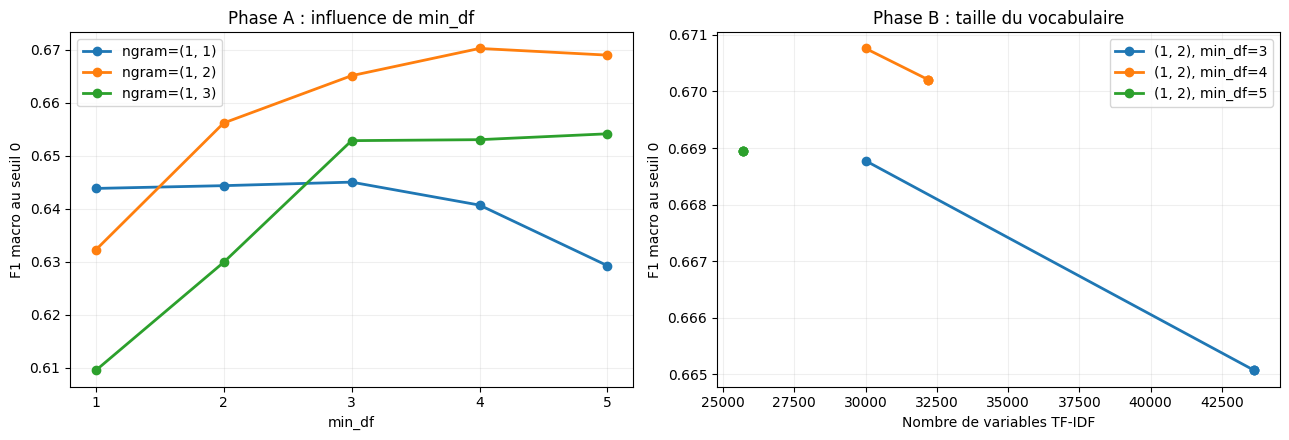


Résumé des trois TF-IDF sélectionnés :


,ngram_range,min_df,max_features,variables_tfidf,f1_macro
0,"(1, 2)",4,30000.0,30000,0.67076
1,"(1, 2)",4,50000.0,32202,0.67021
2,"(1, 2)",4,70000.0,32202,0.67021


In [35]:
figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)


for ngram, groupe in phase_A.groupby("ngram_range"):

    groupe = groupe.sort_values("min_df")

    axes[0].plot(
        groupe["min_df"],
        groupe["f1_macro"],
        marker="o",
        linewidth=2,
        label=f"ngram={ngram}",
    )

axes[0].set_title("Phase A : influence de min_df")
axes[0].set_xlabel("min_df")
axes[0].set_ylabel("F1 macro au seuil 0")
axes[0].set_xticks(GRILLE_MIN_DF)
axes[0].legend()
axes[0].grid(alpha=0.2)


for (ngram, min_df), groupe in phase_B.groupby(
    ["ngram_range", "min_df"]
):

    groupe = groupe.sort_values("variables_tfidf")

    axes[1].plot(
        groupe["variables_tfidf"],
        groupe["f1_macro"],
        marker="o",
        linewidth=2,
        label=f"{ngram}, min_df={min_df}",
    )

axes[1].set_title("Phase B : taille du vocabulaire")
axes[1].set_xlabel("Nombre de variables TF-IDF")
axes[1].set_ylabel("F1 macro au seuil 0")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


print("\nRésumé des trois TF-IDF sélectionnés :")

display(
    meilleurs_B[
        [
            "ngram_range",
            "min_df",
            "max_features",
            "variables_tfidf",
            "f1_macro",
        ]
    ].round(5)
)

## 10. Recherche des hyperparamètres SVM

Sur la base des trois représentations TF-IDF sélectionnées, il faut maintenant explorer les paramètres du classifieur LinearSVC :

- C ∈ {0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.8, 1}
- class_weight ∈ {None, balanced}

La pondération balanced adapte les poids des classes à leur fréquence et le paramètre C contrôle la force de régularisation :

- Un C faible correspond à une régularisation plus forte.
- Un C élevé correspond à une régularisation plus faible.

Pour chaque combinaison TF-IDF + SVM :

1. Entraîner les huit classifieurs binaires.
2. Calculer les marges de décision sur validation.
3. Évaluer les performances au seuil standard zéro.
4. Optimiser exhaustivement les huit seuils.
5. Réévaluer les performances avec les seuils optimisés.
6. Enregistrer les résultats et les seuils.

Le critère principal est le F1 macro après optimisation des seuils.

In [36]:
GRILLE_C = [
    0.01,
    0.03,
    0.05,
    0.1,
    0.15,
    0.2,
    0.3,
    0.5,
    0.8,
    1,
]

GRILLE_CLASS_WEIGHT = [
    None,
    "balanced",
]

N_TFIDF = len(configurations_tfidf_finalistes)

N_CONFIGURATIONS = (
    N_TFIDF
    * len(GRILLE_C)
    * len(GRILLE_CLASS_WEIGHT)
)


print(f"Représentations TF-IDF : {N_TFIDF}")
print(f"Valeurs de C : {len(GRILLE_C)}")
print(f"Pondérations : {len(GRILLE_CLASS_WEIGHT)}")

print(f"\nConfigurations SVM : {N_CONFIGURATIONS}")
print(f"Optimisations de seuils : {N_CONFIGURATIONS}")

print(
    f"Recherches individuelles de seuils : "
    f"{N_CONFIGURATIONS * len(TAGS)}"
)

print("\nCritère de sélection : F1 macro optimisé")

Représentations TF-IDF : 3
Valeurs de C : 10
Pondérations : 2

Configurations SVM : 60
Optimisations de seuils : 60
Recherches individuelles de seuils : 480

Critère de sélection : F1 macro optimisé


## 11. Exécution de la recherche SVM

Cette cellule constitue le cœur de l'optimisation. Chaque représentation TF-IDF est entraînée une seule fois pour l'ensemble de ses 14 configurations SVM.

Les matrices vectorisées sont réutilisées pour tous les SVM associés, avec conservation du meilleur modèle courant en mémoire. Les résultats des expériences et les seuils sont sauvegardés progressivement pour faciliter le suivi.

Pour chaque configuration :

- Identifiant de l'essai.
- Représentation TF-IDF.
- Valeur de C.
- Pondération des classes.
- F1 macro au seuil zéro.
- F1 macro après optimisation.
- Gain apporté par les seuils.
- Temps d'entraînement.

Un indicateur signale chaque nouveau meilleur modèle.

In [37]:
resultats_svm = []
resultats_seuils = []

meilleur_modele = None
meilleure_cle = None

numero_essai = 0
debut_recherche_svm = perf_counter()


for indice_tfidf, config in enumerate(
    configurations_tfidf_finalistes,
    start=1,
):

    identifiant_tfidf = f"T{indice_tfidf}"

    print("\n" + "=" * 72)
    print(f"REPRÉSENTATION TF-IDF {indice_tfidf}/{N_TFIDF}")
    print("=" * 72)
    print(f"Paramètres : {config}")

    debut_vectorisation = perf_counter()

    vectoriseur = creer_vectoriseur(config)

    X_train = vectoriseur.fit_transform(textes_train)
    X_val = vectoriseur.transform(textes_val)

    temps_vectorisation = (
        perf_counter() - debut_vectorisation
    )

    n_variables = X_train.shape[1]

    print(f"Variables TF-IDF : {n_variables:,}")
    print(f"Temps de vectorisation : {temps_vectorisation:.2f}s")

    assert sparse.issparse(X_train)
    assert sparse.issparse(X_val)

    assert X_train.shape[0] == len(y_train)
    assert X_val.shape[0] == len(y_val)

    for C, class_weight in product(
        GRILLE_C,
        GRILLE_CLASS_WEIGHT,
    ):

        numero_essai += 1

        identifiant_essai = f"S{numero_essai:03d}"

        modele = creer_svm(
            C=C,
            class_weight=class_weight,
        )


        debut_fit = perf_counter()

        with threadpool_limits(limits=1):
            modele.fit(X_train, y_train)

        temps_fit = perf_counter() - debut_fit


        debut_scores = perf_counter()

        with threadpool_limits(limits=1):
            scores = modele.decision_function(X_val)

        temps_scores = perf_counter() - debut_scores

        scores = np.asarray(scores)

        assert scores.shape == y_val.shape
        assert np.isfinite(scores).all()


        predictions_zero = (
            scores >= 0.0
        ).astype(np.int8)

        metriques_zero = evaluer_predictions(
            y_val,
            predictions_zero,
        )


        debut_optimisation = perf_counter()

        seuils, details = optimiser_seuils(
            scores,
            y_val,
        )

        temps_optimisation = (
            perf_counter() - debut_optimisation
        )

        predictions_optimisees = (
            scores >= seuils
        ).astype(np.int8)

        metriques_optimisees = evaluer_predictions(
            y_val,
            predictions_optimisees,
        )

        assert (
            metriques_optimisees["f1_macro"]
            >= metriques_zero["f1_macro"] - 1e-12
        )


        ligne = {
            "ordre": numero_essai,
            "essai": identifiant_essai,
            "id_tfidf": identifiant_tfidf,

            "ngram_range": str(config["ngram_range"]),
            "min_df": config["min_df"],
            "max_features": config["max_features"],

            "sublinear_tf": True,
            "variables_tfidf": n_variables,

            "C": float(C),
            "class_weight": (
                "None"
                if class_weight is None
                else "balanced"
            ),

            "f1_macro_zero": metriques_zero["f1_macro"],
            "f1_macro_optimise": metriques_optimisees["f1_macro"],

            "gain_f1_macro": (
                metriques_optimisees["f1_macro"]
                - metriques_zero["f1_macro"]
            ),

            "f1_micro_zero": metriques_zero["f1_micro"],
            "f1_micro_optimise": metriques_optimisees["f1_micro"],

            "precision_macro_optimise": (
                metriques_optimisees["precision_macro"]
            ),

            "rappel_macro_optimise": (
                metriques_optimisees["rappel_macro"]
            ),

            "exact_match_ratio_optimise": (
                metriques_optimisees["exact_match_ratio"]
            ),

            "hamming_loss_optimise": (
                metriques_optimisees["hamming_loss"]
            ),

            "temps_vectorisation_s": temps_vectorisation,
            "temps_fit_s": temps_fit,
            "temps_scores_s": temps_scores,
            "temps_optimisation_seuils_s": temps_optimisation,
        }

        resultats_svm.append(ligne)


        details = details.copy()

        details.insert(
            0,
            "essai",
            identifiant_essai,
        )

        details.insert(
            1,
            "id_tfidf",
            identifiant_tfidf,
        )

        details["C"] = float(C)

        details["class_weight"] = (
            "None"
            if class_weight is None
            else "balanced"
        )

        resultats_seuils.append(details)


        cle_candidat = (
            -metriques_optimisees["f1_macro"],
            n_variables,
            float(C),
            numero_essai,
        )

        nouveau_meilleur = (
            meilleure_cle is None
            or cle_candidat < meilleure_cle
        )

        if nouveau_meilleur:

            meilleure_cle = cle_candidat

            meilleur_modele = {
                "vectoriseur": vectoriseur,
                "classifieur": modele,
                "seuils": seuils.copy(),

                "configuration_tfidf": config.copy(),

                "C": float(C),
                "class_weight": class_weight,

                "essai": identifiant_essai,
                "id_tfidf": identifiant_tfidf,

                "scores_validation": scores.copy(),
                "resultat": ligne.copy(),
            }


        print(
            f"[{numero_essai:02d}/{N_CONFIGURATIONS}] "
            f"{identifiant_essai} | "
            f"{identifiant_tfidf} | "
            f"C={C:<5} | "
            f"weight={str(class_weight):<8} | "
            f"F1(0)={metriques_zero['f1_macro']:.4f} | "
            f"F1(opt)={metriques_optimisees['f1_macro']:.4f} | "
            f"gain={ligne['gain_f1_macro']:+.4f} | "
            f"fit={temps_fit:.2f}s"
            + (" | MEILLEUR" if nouveau_meilleur else ""),
            flush=True,
        )


        pd.DataFrame(
            resultats_svm
        ).to_csv(
            DOSSIER_SORTIE / "recherche_svm.csv",
            index=False,
        )

        pd.concat(
            resultats_seuils,
            ignore_index=True,
        ).to_csv(
            DOSSIER_SORTIE / "recherche_seuils.csv",
            index=False,
        )

        del modele, scores
        gc.collect()

    del X_train, X_val
    gc.collect()


duree_recherche_svm = (
    perf_counter() - debut_recherche_svm
)

recherche_svm = pd.DataFrame(resultats_svm)

recherche_seuils = pd.concat(
    resultats_seuils,
    ignore_index=True,
)


assert len(recherche_svm) == N_CONFIGURATIONS

assert len(recherche_seuils) == (
    N_CONFIGURATIONS * len(TAGS)
)


print("\n" + "=" * 72)
print("RECHERCHE SVM TERMINÉE")
print("=" * 72)

print(f"Essais réalisés : {len(recherche_svm)}")

print(
    f"Durée totale : "
    f"{duree_recherche_svm / 60:.2f} minutes"
)

print(f"Meilleur essai : {meilleur_modele['essai']}")

print(
    f"Meilleur F1 macro : "
    f"{meilleur_modele['resultat']['f1_macro_optimise']:.5f}"
)

print("\nConfiguration retenue :")
print(meilleur_modele["configuration_tfidf"])

print(f"C : {meilleur_modele['C']}")
print(f"class_weight : {meilleur_modele['class_weight']}")


REPRÉSENTATION TF-IDF 1/3
Paramètres : {'ngram_range': (1, 2), 'min_df': 4, 'max_features': 30000}
Variables TF-IDF : 30,000
Temps de vectorisation : 1.16s
[01/60] S001 | T1 | C=0.01  | weight=None     | F1(0)=0.0000 | F1(opt)=0.6607 | gain=+0.6607 | fit=0.15s | MEILLEUR
[02/60] S002 | T1 | C=0.01  | weight=balanced | F1(0)=0.6146 | F1(opt)=0.6618 | gain=+0.0473 | fit=0.19s | MEILLEUR
[03/60] S003 | T1 | C=0.03  | weight=None     | F1(0)=0.0438 | F1(opt)=0.6747 | gain=+0.6309 | fit=0.19s | MEILLEUR
[04/60] S004 | T1 | C=0.03  | weight=balanced | F1(0)=0.6364 | F1(opt)=0.6736 | gain=+0.0373 | fit=0.28s
[05/60] S005 | T1 | C=0.05  | weight=None     | F1(0)=0.1437 | F1(opt)=0.6785 | gain=+0.5348 | fit=0.21s | MEILLEUR
[06/60] S006 | T1 | C=0.05  | weight=balanced | F1(0)=0.6550 | F1(opt)=0.6800 | gain=+0.0250 | fit=0.39s | MEILLEUR
[07/60] S007 | T1 | C=0.1   | weight=None     | F1(0)=0.2232 | F1(opt)=0.6957 | gain=+0.4725 | fit=0.18s | MEILLEUR
[08/60] S008 | T1 | C=0.1   | weight=balan

## 12. Classement général des configurations

Les modèles selon le F1 macro après optimisation des seuils doivent être classés en analysant également :

- le F1 macro avant optimisation ;
- le gain apporté par les seuils ;
- le F1 micro ;
- la précision et le rappel macro ;
- l'Exact Match Ratio ;
- le nombre de variables TF-IDF.

L'objectif est de vérifier si le meilleur candidat domine clairement
les autres ou si plusieurs configurations présentent des performances
très proches.

In [38]:
classement_svm = recherche_svm.sort_values(
    [
        "f1_macro_optimise",
        "variables_tfidf",
        "C",
        "ordre",
    ],
    ascending=[False, True, True, True],
    kind="stable",
).reset_index(drop=True)


colonnes_classement = [
    "essai",
    "id_tfidf",
    "ngram_range",
    "min_df",
    "max_features",
    "variables_tfidf",
    "C",
    "class_weight",
    "f1_macro_zero",
    "f1_macro_optimise",
    "gain_f1_macro",
    "f1_micro_optimise",
    "exact_match_ratio_optimise",
]


print("=" * 72)
print("TOP 15 DES CONFIGURATIONS")
print("=" * 72)

afficher_top(
    classement_svm,
    colonnes_classement,
    n=15,
)


print("\nStatistiques générales :")

print(
    f"Meilleur F1 au seuil 0 : "
    f"{recherche_svm['f1_macro_zero'].max():.5f}"
)

print(
    f"Meilleur F1 après optimisation : "
    f"{recherche_svm['f1_macro_optimise'].max():.5f}"
)

print(
    f"Gain moyen des seuils : "
    f"{recherche_svm['gain_f1_macro'].mean():+.5f}"
)

print(
    f"Gain maximal des seuils : "
    f"{recherche_svm['gain_f1_macro'].max():+.5f}"
)


print("\nMeilleur modèle :")

display(
    pd.DataFrame([
        meilleur_modele["resultat"]
    ]).round(5)
)


if len(classement_svm) >= 2:

    ecart = (
        classement_svm.iloc[0]["f1_macro_optimise"]
        - classement_svm.iloc[1]["f1_macro_optimise"]
    )

    print(
        f"\nÉcart entre les deux meilleurs candidats : "
        f"{ecart:.5f}"
    )

TOP 15 DES CONFIGURATIONS


,essai,id_tfidf,ngram_range,min_df,max_features,variables_tfidf,C,class_weight,f1_macro_zero,f1_macro_optimise,gain_f1_macro,f1_micro_optimise,exact_match_ratio_optimise
0,S035,T2,"(1, 2)",4,50000,32202,0.5,None,0.44424,0.71208,0.26784,0.65400,0.59540
1,S055,T3,"(1, 2)",4,70000,32202,0.5,None,0.44424,0.71208,0.26784,0.65400,0.59540
2,S015,T1,"(1, 2)",4,30000,30000,0.5,None,0.44577,0.71063,0.26486,0.65465,0.59675
3,S033,T2,"(1, 2)",4,50000,32202,0.3,None,0.39224,0.70891,0.31668,0.65507,0.58593
4,S053,T3,"(1, 2)",4,70000,32202,0.3,None,0.39224,0.70891,0.31668,0.65507,0.58593
5,S017,T1,"(1, 2)",4,30000,30000,0.8,None,0.49492,0.70842,0.21350,0.65081,0.56834
6,S013,T1,"(1, 2)",4,30000,30000,0.3,None,0.39259,0.70827,0.31568,0.65437,0.58728
7,S037,T2,"(1, 2)",4,50000,32202,0.8,None,0.49323,0.70699,0.21376,0.65058,0.56969
8,S057,T3,"(1, 2)",4,70000,32202,0.8,None,0.49323,0.70699,0.21376,0.65058,0.56969
9,S019,T1,"(1, 2)",4,30000,30000,1.0,None,0.51737,0.70577,0.18840,0.64767,0.56563



Statistiques générales :
Meilleur F1 au seuil 0 : 0.67193
Meilleur F1 après optimisation : 0.71208
Gain moyen des seuils : +0.22472
Gain maximal des seuils : +0.66071

Meilleur modèle :


,ordre,essai,id_tfidf,ngram_range,min_df,max_features,sublinear_tf,variables_tfidf,C,class_weight,f1_macro_zero,f1_macro_optimise,gain_f1_macro,f1_micro_zero,f1_micro_optimise,precision_macro_optimise,rappel_macro_optimise,exact_match_ratio_optimise,hamming_loss_optimise,temps_vectorisation_s,temps_fit_s,temps_scores_s,temps_optimisation_seuils_s
0,35,S035,T2,"(1, 2)",4,50000,True,32202,0.5,None,0.44424,0.71208,0.26784,0.47936,0.654,0.77094,0.66893,0.5954,0.05853,1.1131,0.23841,0.00361,0.00234



Écart entre les deux meilleurs candidats : 0.00000


## 13. Influence de C et class_weight

Il faut étudier l'effet des hyperparamètres SVM. Pour chaque représentation TF-IDF, le F1 macro est tracé après optimisation des seuils en fonction de C. Cette visualisation permet de déterminer :

- si les performances sont sensibles à la régularisation ;
- si la pondération balanced apporte un gain ;
- si le meilleur C est situé dans une zone stable ;
- si les différentes représentations TF-IDF réagissent différemment.

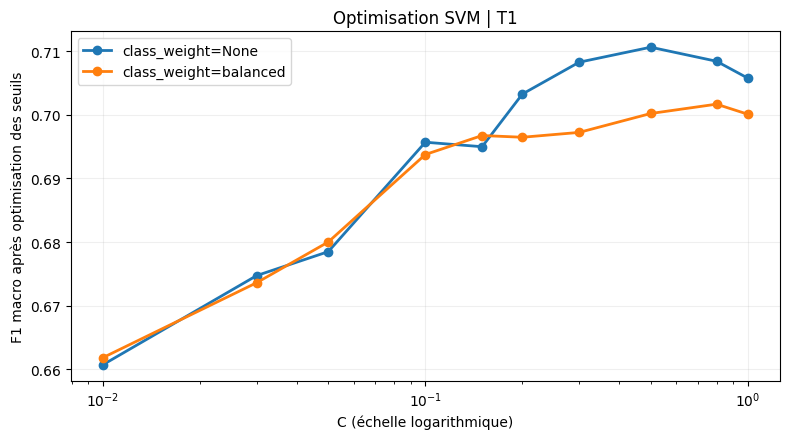

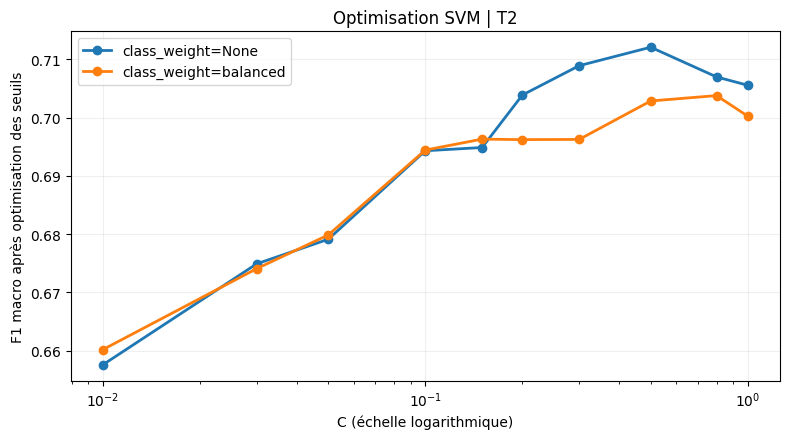

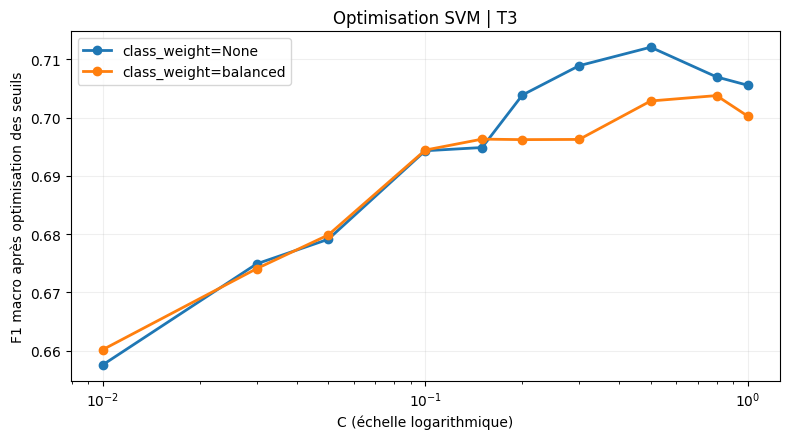


Meilleur SVM pour chaque TF-IDF :


,id_tfidf,variables_tfidf,C,class_weight,f1_macro_zero,f1_macro_optimise,gain_f1_macro
0,T2,32202,0.5,None,0.44424,0.71208,0.26784
1,T3,32202,0.5,None,0.44424,0.71208,0.26784
2,T1,30000,0.5,None,0.44577,0.71063,0.26486


In [39]:
for identifiant_tfidf in recherche_svm["id_tfidf"].unique():

    donnees = recherche_svm.loc[
        recherche_svm["id_tfidf"] == identifiant_tfidf
    ]

    figure, axe = plt.subplots(figsize=(8, 4.5))

    for ponderation, groupe in donnees.groupby(
        "class_weight"
    ):

        groupe = groupe.sort_values("C")

        axe.plot(
            groupe["C"],
            groupe["f1_macro_optimise"],
            marker="o",
            linewidth=2,
            label=f"class_weight={ponderation}",
        )

    axe.set_xscale("log")

    axe.set_title(
        f"Optimisation SVM | {identifiant_tfidf}"
    )

    axe.set_xlabel("C (échelle logarithmique)")
    axe.set_ylabel("F1 macro après optimisation des seuils")

    axe.grid(alpha=0.2)
    axe.legend()

    plt.tight_layout()
    plt.show()


meilleurs_par_tfidf = (
    classement_svm
    .drop_duplicates("id_tfidf")
    .reset_index(drop=True)
)


print("\nMeilleur SVM pour chaque TF-IDF :")

display(
    meilleurs_par_tfidf[
        [
            "id_tfidf",
            "variables_tfidf",
            "C",
            "class_weight",
            "f1_macro_zero",
            "f1_macro_optimise",
            "gain_f1_macro",
        ]
    ].round(5)
)

## 14. Performances du modèle final

Évaluation de la configuration sélectionnée. Deux versions de ses prédictions sont comparées :

- Seuil standard zéro pour les huit catégories.
- Seuil optimisé individuellement pour chaque catégorie.

Cette comparaison permet d'isoler le gain apporté par l'ajustement
des seuils pour le modèle retenu. Les métriques principales sont :

- F1 macro
- F1 micro
- Précision macro
- Rappel macro
- Exact Match Ratio
- Hamming Loss

Les performances restent mesurées sur la validation utilisée
pour la sélection. Elles ne constituent pas une évaluation indépendante.

In [40]:
scores_finaux = meilleur_modele["scores_validation"]
seuils_finaux = meilleur_modele["seuils"]

predictions_zero = (
    scores_finaux >= 0.0
).astype(np.int8)

predictions_finales = (
    scores_finaux >= seuils_finaux
).astype(np.int8)


metriques_zero = evaluer_predictions(
    y_val,
    predictions_zero,
)

metriques_finales = evaluer_predictions(
    y_val,
    predictions_finales,
)


comparaison_globale = pd.DataFrame([
    {
        "configuration": "Seuil standard 0",
        **metriques_zero,
    },
    {
        "configuration": "Seuils optimisés",
        **metriques_finales,
    },
])


print("=" * 72)
print("PERFORMANCES DU MODÈLE FINAL")
print("=" * 72)

display(
    comparaison_globale.round(5)
)


print("\nGains après optimisation des seuils :")

for metrique in [
    "f1_macro",
    "f1_micro",
    "precision_macro",
    "rappel_macro",
    "exact_match_ratio",
    "hamming_loss",
]:
    difference = (
        metriques_finales[metrique]
        - metriques_zero[metrique]
    )

    print(
        f"{metrique:<25} : {difference:+.5f}"
    )


comparaison_globale.to_csv(
    DOSSIER_SORTIE / "metriques_validation.csv",
    index=False,
)

PERFORMANCES DU MODÈLE FINAL


,configuration,f1_macro,f1_micro,precision_macro,rappel_macro,exact_match_ratio,hamming_loss
0,Seuil standard 0,0.44424,0.47936,0.85179,0.32354,0.55886,0.06614
1,Seuils optimisés,0.71208,0.65400,0.77094,0.66893,0.59540,0.05853



Gains après optimisation des seuils :
f1_macro                  : +0.26784
f1_micro                  : +0.17464
precision_macro           : -0.08085
rappel_macro              : +0.34539
exact_match_ratio         : +0.03654
hamming_loss              : -0.00761


## 15. Analyse des performances par catégorie

Le F1 macro donne une vision globale, mais ne montre pas les différences
entre les huit catégories. Il faut donc calculer pour chaque tag :

- Le nombre de positifs réels.
- Le seuil optimisé.
- Le F1 avant et après optimisation.
- La précision.
- Le rappel.
- Le nombre de prédictions positives.

Cette analyse est particulièrement importante pour les catégories rares,
dont le F1 peut varier fortement à cause de quelques exemples.

PERFORMANCES PAR CATÉGORIE


,tag,support,seuil_optimise,f1_zero,f1_optimise,gain_f1,precision_optimise,rappel_optimise,positifs_predits_zero,positifs_predits_optimise
0,math,211,-0.24629,0.45342,0.60000,0.14658,0.58904,0.61137,111,219
1,graphs,81,-0.38137,0.53782,0.66216,0.12435,0.73134,0.60494,38,67
2,strings,63,-0.38606,0.50000,0.69697,0.19697,0.66667,0.73016,37,69
3,number_theory,52,-0.48764,0.42424,0.63265,0.20841,0.67391,0.59615,14,46
4,trees,49,-0.37645,0.63158,0.71739,0.08581,0.76744,0.67347,27,43
5,geometry,25,-0.45178,0.20690,0.70833,0.50144,0.73913,0.68000,4,23
6,games,16,-0.36850,0.66667,0.89655,0.22989,1.00000,0.81250,8,13
7,probabilities,14,-0.50397,0.13333,0.78261,0.64928,1.00000,0.64286,1,9


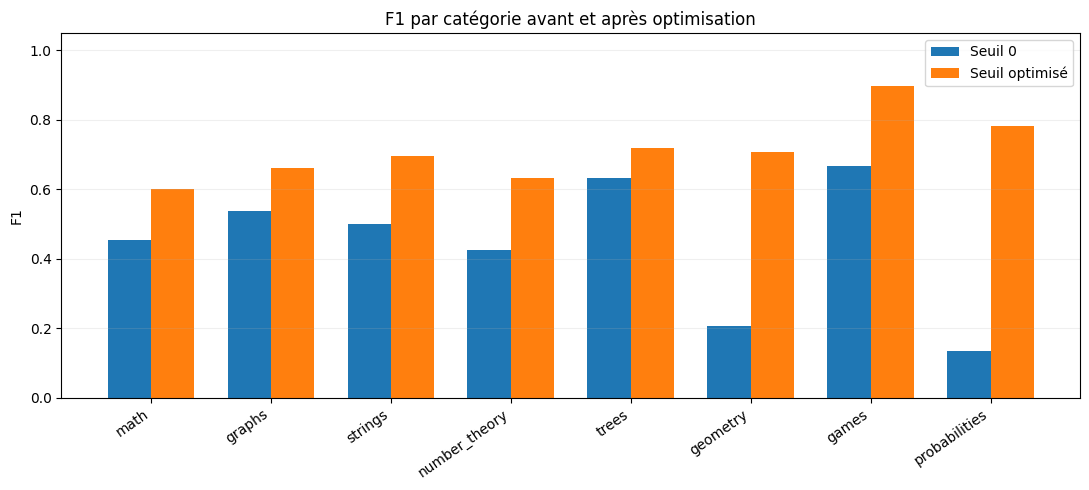

In [41]:
tags_zero = metriques_par_tag(
    y_val,
    predictions_zero,
    np.zeros(len(TAGS)),
)

tags_optimises = metriques_par_tag(
    y_val,
    predictions_finales,
    seuils_finaux,
)


comparaison_tags = tags_zero.merge(
    tags_optimises,
    on=["tag", "support"],
    suffixes=("_zero", "_optimise"),
)

comparaison_tags["gain_f1"] = (
    comparaison_tags["f1_optimise"]
    - comparaison_tags["f1_zero"]
)


print("=" * 72)
print("PERFORMANCES PAR CATÉGORIE")
print("=" * 72)

display(
    comparaison_tags[
        [
            "tag",
            "support",
            "seuil_optimise",
            "f1_zero",
            "f1_optimise",
            "gain_f1",
            "precision_optimise",
            "rappel_optimise",
            "positifs_predits_zero",
            "positifs_predits_optimise",
        ]
    ].round(5)
)


comparaison_tags.to_csv(
    DOSSIER_SORTIE / "metriques_par_tag_validation.csv",
    index=False,
)


figure, axe = plt.subplots(figsize=(11, 5))

positions = np.arange(len(TAGS))
largeur = 0.36

axe.bar(
    positions - largeur / 2,
    comparaison_tags["f1_zero"],
    width=largeur,
    label="Seuil 0",
)

axe.bar(
    positions + largeur / 2,
    comparaison_tags["f1_optimise"],
    width=largeur,
    label="Seuil optimisé",
)

axe.set_xticks(positions)
axe.set_xticklabels(
    TAGS,
    rotation=35,
    ha="right",
)

axe.set_title(
    "F1 par catégorie avant et après optimisation"
)

axe.set_ylabel("F1")
axe.set_ylim(0, 1.05)

axe.grid(axis="y", alpha=0.2)
axe.legend()

plt.tight_layout()
plt.show()

## 16. Analyse des erreurs

Pour mieux comprendre le comportement du modèle, il faut calculer la matrice de confusion binaire de chaque catégorie. Pour chaque tag :

- TP : vrais positifs.
- FP : faux positifs.
- FN : faux négatifs.
- TN : vrais négatifs.

Cette analyse permet d'identifier :

- les catégories présentant un déficit de rappel ;
- les catégories générant trop de faux positifs ;
- les exercices comportant plusieurs erreurs de classification.

Les résultats doivent être interprétés en tenant compte du support
de chaque catégorie.

ANALYSE DES ERREURS


,tag,support,TP,FP,FN,TN,erreurs
0,math,211,129,90,82,438,172
1,graphs,81,49,18,32,640,50
2,strings,63,46,23,17,653,40
3,number_theory,52,31,15,21,672,36
4,trees,49,33,10,16,680,26
5,geometry,25,17,6,8,708,14
6,probabilities,14,9,0,5,725,5
7,games,16,13,0,3,723,3



Erreurs au niveau des exercices :
Exercices parfaitement classés : 440
Exercices avec erreur : 299
Nombre moyen de tags incorrects : 0.4682


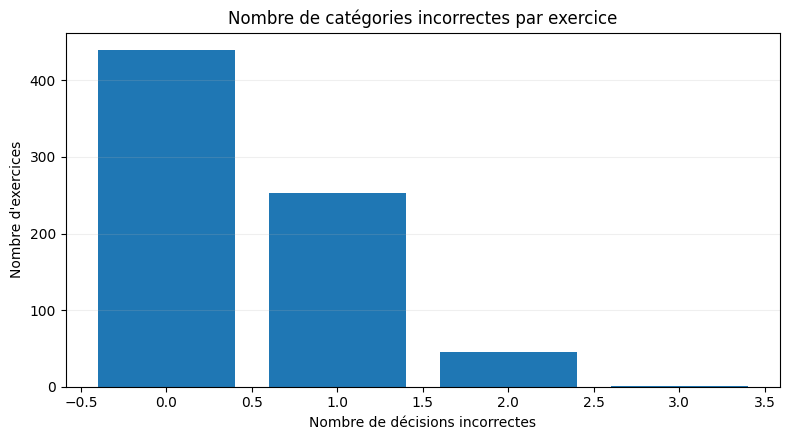

In [42]:
lignes_erreurs = []

for j, tag in enumerate(TAGS):

    reels = y_val[:, j]
    predits = predictions_finales[:, j]

    tp = int(np.sum((reels == 1) & (predits == 1)))
    fp = int(np.sum((reels == 0) & (predits == 1)))
    fn = int(np.sum((reels == 1) & (predits == 0)))
    tn = int(np.sum((reels == 0) & (predits == 0)))

    lignes_erreurs.append({
        "tag": tag,
        "support": tp + fn,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "erreurs": fp + fn,
    })


analyse_erreurs = pd.DataFrame(
    lignes_erreurs
).sort_values(
    "erreurs",
    ascending=False,
).reset_index(drop=True)


print("=" * 72)
print("ANALYSE DES ERREURS")
print("=" * 72)

display(analyse_erreurs)


erreurs_exercices = np.sum(
    predictions_finales != y_val,
    axis=1,
)

exactement_corrects = int(
    np.sum(erreurs_exercices == 0)
)

avec_erreurs = int(
    np.sum(erreurs_exercices > 0)
)


print("\nErreurs au niveau des exercices :")

print(f"Exercices parfaitement classés : {exactement_corrects}")
print(f"Exercices avec erreur : {avec_erreurs}")

print(
    f"Nombre moyen de tags incorrects : "
    f"{erreurs_exercices.mean():.4f}"
)


distribution_erreurs = pd.Series(
    erreurs_exercices
).value_counts().sort_index()

figure, axe = plt.subplots(figsize=(8, 4.5))

axe.bar(
    distribution_erreurs.index,
    distribution_erreurs.values,
)

axe.set_title(
    "Nombre de catégories incorrectes par exercice"
)

axe.set_xlabel("Nombre de décisions incorrectes")
axe.set_ylabel("Nombre d'exercices")
axe.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


analyse_erreurs.to_csv(
    DOSSIER_SORTIE / "analyse_erreurs.csv",
    index=False,
)

## 17. Inspection qualitative des erreurs

Les métriques quantitatives ne permettent pas toujours de comprendre
pourquoi un exercice a été mal classé. Il faut donc inspecter quelques exercices de validation présentant le plus grand nombre de décisions incorrectes.

Pour chaque exemple, il faut affichier :

- Les catégories réelles.
- Les catégories prédites.
- Les faux positifs.
- Les faux négatifs.
- Un extrait de l'énoncé.

Cette inspection reste descriptive. Elle ne sert pas à modifier
les hyperparamètres ou les seuils après leur sélection.

In [43]:
N_EXEMPLES_ERREURS = 5

indices_erreurs = np.argsort(
    -erreurs_exercices,
    kind="stable",
)

indices_erreurs = [
    int(i)
    for i in indices_erreurs
    if erreurs_exercices[i] > 0
][:N_EXEMPLES_ERREURS]


def tags_actifs(vecteur):
    return [
        tag
        for tag, valeur in zip(TAGS, vecteur)
        if valeur == 1
    ]


print("=" * 72)
print("EXEMPLES D'ERREURS")
print("=" * 72)


if not indices_erreurs:
    print("Aucune erreur sur la validation.")

else:
    for rang, indice in enumerate(indices_erreurs, start=1):

        reels = y_val[indice]
        predits = predictions_finales[indice]

        faux_positifs = [
            TAGS[j]
            for j in range(len(TAGS))
            if reels[j] == 0 and predits[j] == 1
        ]

        faux_negatifs = [
            TAGS[j]
            for j in range(len(TAGS))
            if reels[j] == 1 and predits[j] == 0
        ]

        print("\n" + "-" * 72)
        print(f"EXEMPLE {rang} | Index validation : {indice}")
        print("-" * 72)

        print(f"Tags réels : {tags_actifs(reels)}")
        print(f"Tags prédits : {tags_actifs(predits)}")

        print(f"Faux positifs : {faux_positifs}")
        print(f"Faux négatifs : {faux_negatifs}")

        print("\nExtrait de l'énoncé :")
        print(textes_val[indice][:800])

EXEMPLES D'ERREURS

------------------------------------------------------------------------
EXEMPLE 1 | Index validation : 391
------------------------------------------------------------------------
Tags réels : ['math', 'number_theory']
Tags prédits : ['graphs']
Faux positifs : ['graphs']
Faux négatifs : ['math', 'number_theory']

Extrait de l'énoncé :
DESCRIPTION
Boy Dima gave Julian a birthday present — set $$$B$$$ consisting of positive integers. However, he didn't know, that Julian hates sets, but enjoys bipartite graphs more than anything else!Julian was almost upset, but her friend Alex said, that he can build an undirected graph using this set in such a way: let all integer numbers be vertices, then connect any two $$$i$$$ and $$$j$$$ with an edge if $$$|i - j|$$$ belongs to $$$B$$$.Unfortunately, Julian doesn't like the graph, that was built using $$$B$$$. Alex decided to rectify the situation, so he wants to erase some numbers from $$$B$$$, so that graph built using the new

## 18. Mesure de la latence d'inférence

Le temps nécessaire pour prédire les catégories d'un exercice individuel est aussi important. Le protocol est le suivant :

- Exécution sur CPU.
- Un seul thread numérique.
- Trois prédictions d'échauffement.
- Mesure individuelle sur tous les exercices de validation.
- Prétraitement, vectorisation et classification inclus.
- Chargement du modèle exclu.


In [44]:
def predire_exercice(exercice, artefact):

    sections = []

    for champ, titre in artefact["champs_texte"].items():

        valeur = exercice.get(champ)

        if not isinstance(valeur, str):
            continue

        valeur = unicodedata.normalize(
            "NFC",
            html.unescape(valeur),
        ).strip()

        if valeur:
            sections.append(f"{titre}\n{valeur}")

    texte = "\n\n".join(sections)

    if not texte.strip():
        raise ValueError("Énoncé vide.")

    X = artefact["vectoriseur"].transform([texte])

    scores = artefact["classifieur"].decision_function(X)

    scores = np.asarray(scores).reshape(-1)

    seuils = np.asarray(
        artefact["seuils"],
        dtype=float,
    )

    return (scores >= seuils).astype(np.int8)


artefact_temporaire = {
    "vectoriseur": meilleur_modele["vectoriseur"],
    "classifieur": meilleur_modele["classifieur"],
    "seuils": meilleur_modele["seuils"],
    "champs_texte": CHAMPS_TEXTE,
}


exercices_val = validation.to_dict("records")


with threadpool_limits(limits=1):

    for exercice in exercices_val[:3]:
        predire_exercice(
            exercice,
            artefact_temporaire,
        )


latences = []

with threadpool_limits(limits=1):

    for exercice in exercices_val:

        debut = perf_counter()

        predire_exercice(
            exercice,
            artefact_temporaire,
        )

        latences.append(
            (perf_counter() - debut) * 1000
        )


latences = np.asarray(latences)


metriques_latence = {
    "latence_moyenne_ms": float(np.mean(latences)),
    "latence_mediane_ms": float(np.median(latences)),
    "latence_p95_ms": float(np.percentile(latences, 95)),
}


print("=" * 72)
print("LATENCE D'INFÉRENCE")
print("=" * 72)

for nom, valeur in metriques_latence.items():
    print(f"{nom:<25} : {valeur:.4f} ms")


pd.DataFrame([
    metriques_latence
]).to_csv(
    DOSSIER_SORTIE / "latence_inference.csv",
    index=False,
)

LATENCE D'INFÉRENCE
latence_moyenne_ms        : 0.5458 ms
latence_mediane_ms        : 0.5329 ms
latence_p95_ms            : 0.7073 ms


## 19. Synthèse des résultats

Cette section résume l'ensemble de la procédure d'optimisation. Il y est présenté :

1. Le nombre de configurations explorées.
2. Les trois représentations TF-IDF finalistes.
3. Les hyperparamètres du meilleur SVM.
4. Le gain apporté par l'optimisation des seuils.
5. Les métriques finales sur validation.
6. La complexité du modèle et sa latence.

In [45]:
nombre_entrainements_tfidf = len(cache_tfidf)

nombre_entrainements_svm = len(recherche_svm)

nombre_total_entrainements = (
    nombre_entrainements_tfidf
    + nombre_entrainements_svm
)


print("=" * 75)
print("SYNTHÈSE FINALE")
print("=" * 75)


print("\n1. RECHERCHE")

print(f"Configurations TF-IDF évaluées : {nombre_entrainements_tfidf}")
print(f"Configurations SVM évaluées : {nombre_entrainements_svm}")

print(
    f"Nombre total d'entraînements : "
    f"{nombre_total_entrainements}"
)


print("\n2. REPRÉSENTATION TF-IDF RETENUE")

for parametre, valeur in meilleur_modele[
    "configuration_tfidf"
].items():

    print(f"{parametre:<20} : {valeur}")

print(
    f"Nombre de variables : "
    f"{meilleur_modele['resultat']['variables_tfidf']:,}"
)


print("\n3. HYPERPARAMÈTRES SVM")

print(f"C : {meilleur_modele['C']}")
print(f"class_weight : {meilleur_modele['class_weight']}")


print("\n4. OPTIMISATION DES SEUILS")

print(
    f"F1 macro au seuil 0 : "
    f"{metriques_zero['f1_macro']:.5f}"
)

print(
    f"F1 macro optimisé : "
    f"{metriques_finales['f1_macro']:.5f}"
)

print(
    f"Gain : "
    f"{metriques_finales['f1_macro'] - metriques_zero['f1_macro']:+.5f}"
)


print("\n5. MÉTRIQUES FINALES")

for nom, valeur in metriques_finales.items():
    print(f"{nom:<25} : {valeur:.5f}")


print("\n6. LATENCE")

print(
    f"Latence médiane : "
    f"{metriques_latence['latence_mediane_ms']:.4f} ms"
)

print(
    f"Latence p95 : "
    f"{metriques_latence['latence_p95_ms']:.4f} ms"
)


print("\n7. CATÉGORIES LES PLUS DIFFICILES")

display(
    tags_optimises.sort_values(
        "f1",
        ascending=True,
    )[
        [
            "tag",
            "support",
            "precision",
            "rappel",
            "f1",
        ]
    ].round(5)
)


print("\n8. LIMITES")

print(
    "Les hyperparamètres et les seuils ont été sélectionnés "
    "sur la même validation."
)

print(
    "Une évaluation indépendante est nécessaire pour "
    "confirmer les performances."
)

SYNTHÈSE FINALE

1. RECHERCHE
Configurations TF-IDF évaluées : 24
Configurations SVM évaluées : 60
Nombre total d'entraînements : 84

2. REPRÉSENTATION TF-IDF RETENUE
ngram_range          : (1, 2)
min_df               : 4
max_features         : 50000
Nombre de variables : 32,202

3. HYPERPARAMÈTRES SVM
C : 0.5
class_weight : None

4. OPTIMISATION DES SEUILS
F1 macro au seuil 0 : 0.44424
F1 macro optimisé : 0.71208
Gain : +0.26784

5. MÉTRIQUES FINALES
f1_macro                  : 0.71208
f1_micro                  : 0.65400
precision_macro           : 0.77094
rappel_macro              : 0.66893
exact_match_ratio         : 0.59540
hamming_loss              : 0.05853

6. LATENCE
Latence médiane : 0.5329 ms
Latence p95 : 0.7073 ms

7. CATÉGORIES LES PLUS DIFFICILES


,tag,support,precision,rappel,f1
0,math,211,0.58904,0.61137,0.60000
3,number_theory,52,0.67391,0.59615,0.63265
1,graphs,81,0.73134,0.60494,0.66216
2,strings,63,0.66667,0.73016,0.69697
5,geometry,25,0.73913,0.68000,0.70833
4,trees,49,0.76744,0.67347,0.71739
7,probabilities,14,1.00000,0.64286,0.78261
6,games,16,1.00000,0.81250,0.89655



8. LIMITES
Les hyperparamètres et les seuils ont été sélectionnés sur la même validation.
Une évaluation indépendante est nécessaire pour confirmer les performances.


## 20. Sauvegarde du modèle final

Le modèle final est sauvegardé dans un artefact unique contenant :

- le vectoriseur TF-IDF entraîné ;
- les huit classifieurs LinearSVC ;
- les huit seuils optimisés ;
- l'ordre des catégories ;
- les règles de prétraitement ;
- les hyperparamètres retenus ;
- les métriques de validation ;
- les versions des bibliothèques ;
- les empreintes des données.

Tous les résultats intermédiaires sont également conservés dans des CSV. Cette sauvegarde permet de reproduire les prédictions sans réentraîner le modèle. 

In [46]:
artefact_final = {
    "nom": "classifier_tfidf_linearsvc",
    "version": "1.0",

    "vectoriseur": meilleur_modele["vectoriseur"],
    "classifieur": meilleur_modele["classifieur"],
    "seuils": meilleur_modele["seuils"].copy(),

    "tags": TAGS,
    "colonnes_cibles": COLONNES_CIBLES,
    "champs_texte": CHAMPS_TEXTE,

    "pretraitement": {
        "html_unescape": True,
        "normalisation_unicode": "NFC",
        "separateur_sections": "\n\n",
        "separateur_titre": "\n",
    },

    "parametres_tfidf": {
        **PARAMETRES_TFIDF_FIXES,
        **meilleur_modele["configuration_tfidf"],
    },

    "parametres_svm": {
        "C": meilleur_modele["C"],
        "class_weight": meilleur_modele["class_weight"],
        "dual": "auto",
        "max_iter": 20000,
        "tol": 1e-4,
        "random_state": SEED,
    },

    "optimisation_seuils": {
        "methode": "recherche_exhaustive",
        "regle_decision": "score >= seuil",
        "critere": "f1_par_tag",
        "departage": "proximite_zero_puis_seuil",
    },

    "selection": {
        "essai": meilleur_modele["essai"],
        "critere": "f1_macro_optimise",
        "f1_macro_validation": metriques_finales["f1_macro"],
    },

    "metriques_validation": metriques_finales,

    "versions": VERSIONS,
    "python": platform.python_version(),
    "seed": SEED,

    "empreintes_donnees": EMPREINTES,
}


CHEMIN_MODELE = DOSSIER_SORTIE / "modele.joblib"

joblib.dump(
    artefact_final,
    CHEMIN_MODELE,
    compress=3,
)


metadata = {
    "nom": artefact_final["nom"],
    "version": artefact_final["version"],

    "essai_retenu": meilleur_modele["essai"],

    "configuration_tfidf": {
        "ngram_range": list(
            meilleur_modele["configuration_tfidf"]["ngram_range"]
        ),
        "min_df": int(
            meilleur_modele["configuration_tfidf"]["min_df"]
        ),
        "max_features": meilleur_modele[
            "configuration_tfidf"
        ]["max_features"],
    },

    "configuration_svm": {
        "C": float(meilleur_modele["C"]),
        "class_weight": meilleur_modele["class_weight"],
    },

    "seuils": {
        tag: float(seuil)
        for tag, seuil in zip(TAGS, seuils_finaux)
    },

    "metriques_validation": metriques_finales,
    "latence": metriques_latence,

    "nombre_entrainements_tfidf": nombre_entrainements_tfidf,
    "nombre_entrainements_svm": nombre_entrainements_svm,

    "versions": VERSIONS,
    "empreintes_donnees": EMPREINTES,
}


with open(
    DOSSIER_SORTIE / "metadata.json",
    "w",
    encoding="utf-8",
) as fichier:

    json.dump(
        metadata,
        fichier,
        indent=2,
        ensure_ascii=False,
    )


print("=" * 72)
print("SAUVEGARDE TERMINÉE")
print("=" * 72)

print("\nFichiers générés :")

for chemin in sorted(DOSSIER_SORTIE.iterdir()):

    if chemin.is_file():
        print(f"  {chemin.name}")

SAUVEGARDE TERMINÉE

Fichiers générés :
  analyse_erreurs.csv
  distribution_tags.csv
  latence_inference.csv
  metadata.json
  metriques_par_tag_validation.csv
  metriques_validation.csv
  modele.joblib
  recherche_seuils.csv
  recherche_svm.csv
  recherche_tfidf.csv
  recherche_tfidf_phase_A.csv
  recherche_tfidf_phase_B.csv


## 21. Conclusion

Cette expérimentation a permis de construire et d'optimiser un modèle
de classification multilabel reposant sur TF-IDF et LinearSVC.

La recherche a été organisée en trois étapes :

1. Exploration des n-grammes et de min_df.
2. Optimisation de la taille du vocabulaire TF-IDF.
3. Recherche conjointe des hyperparamètres SVM et des seuils de décision.

L'optimisation exhaustive des seuils a été réalisée pour chaque
combinaison SVM, et non uniquement pour le meilleur modèle au seuil zéro.

Les tableaux précédents permettent d'identifier :

- la meilleure représentation TF-IDF ;
- les hyperparamètres SVM retenus ;
- le gain apporté par les seuils ;
- les performances globales et par catégorie ;
- les principales erreurs ;
- la latence d'inférence.

La recherche en entonnoir ne garantit pas de trouver l'optimum global.

Les configurations TF-IDF sont présélectionnées avec un SVM fixe
au seuil zéro. Une représentation écartée pourrait donc obtenir
de meilleures performances après une optimisation différente.

Par ailleurs, les hyperparamètres et les seuils ont été sélectionnés
sur la même validation. Les performances observées peuvent être
optimistes, notamment pour les catégories rares.